# Study 2: What do the learned agents do?

- This notebook uses the five-seed policies saved by notebook 03.
- It looks at action choices, regional differences, spending, development, and pollution on the same 20 held-out starts.
- The tables and graph stay in this notebook. It does not train agents or save new result files.

## Settings

In [53]:
import json

import matplotlib.pyplot as plt
import pandas as pd

from study_2_economic_sustainability.agents import TabularQLearner
from study_2_economic_sustainability.environment import EconomicSustainabilityEnvironment

In [54]:
REWARD_MODES = ("local", "global", "mixed")
TRAINING_SEEDS = (11, 23, 37, 41, 53)
EVALUATION_SEEDS = tuple(range(100_000, 100_020))
Q_TABLE_DIRECTORY = "../results/reward_comparison"
ACTION_NAMES = {0: "save", 1: "develop", 2: "low", 3: "medium", 4: "high"}

## Load the saved policies

- Each JSON file holds four Q-tables, one for each region.
- We will choose greedy actions during evaluation, with no random exploration.

In [55]:
agents_by_run = {}

for reward_mode in REWARD_MODES:
    for training_seed in TRAINING_SEEDS:
        filename = f"{Q_TABLE_DIRECTORY}/q_{reward_mode}_{training_seed}.json"
        with open(filename, encoding="utf-8") as file:
            tables = json.load(file)

        agents = []
        for region, table in enumerate(tables):
            agent = TabularQLearner(region)
            for key, values in table.items():
                observation = tuple(int(value) for value in key.split(","))
                agent.q[observation] = values
            agents.append(agent)

        agents_by_run[(reward_mode, training_seed)] = agents

print(f"Loaded {len(agents_by_run)} trained policies")

Loaded 15 trained policies


## Record action choices

- One row represents one region at one step.
- The environment still updates all four regions together.

In [56]:
def step_rows(step, observations, edi_before, actions, info, failed):
    rows = []

    for region in range(4):
        rows.append({
            "step": step,
            "region": region,
            "action": actions[region],
            "edi_before": edi_before[region],
            "edi_after": info["development_indices"][region],
            "global_pollution_bin_before": observations[region][3],
            "cost_paid": info["costs_paid"][region],
            "valid": info["valid_actions"][region],
            "pollution_after": info["pollution_loads"][region],
            "gpi_after": info["global_pollution_index"],
            "failed": failed,
        })

    return rows

In [58]:
def collect_episode_actions(agents, reward_mode, seed):
    environment = EconomicSustainabilityEnvironment(reward_mode)
    observations = environment.reset(seed)
    rows = []

    while True:
        edi_before = environment.development_indices
        observations_before = observations
        actions = []
        for region in range(4):
            action = agents[region].select_action(observations[region], greedy=True)
            actions.append(action)

        observations, rewards, terminated, truncated, info = environment.step(tuple(actions))
        rows.extend(step_rows(
            environment.step_count, observations_before, edi_before,
            actions, info, terminated,
        ))
        if terminated or truncated:
            break

    return rows

In [59]:
action_rows = []

for reward_mode in REWARD_MODES:
    for training_seed in TRAINING_SEEDS:
        agents = agents_by_run[(reward_mode, training_seed)]

        for environment_seed in EVALUATION_SEEDS:
            rows = collect_episode_actions(agents, reward_mode, environment_seed)
            for row in rows:
                row["reward_mode"] = reward_mode
                row["training_seed"] = training_seed
                row["environment_seed"] = environment_seed
            action_rows.extend(rows)

actions = pd.DataFrame(action_rows)
print(f"Recorded {len(actions):,} region-steps")

Recorded 240,000 region-steps


## Actions over time

- Each row of the table is one reward mode during one stage.
- The five percentages in a row add to 100.

In [60]:
actions["stage"] = pd.cut(
    actions["step"],
    bins=(0, 50, 100, 150, 200),
    labels=("1-50", "51-100", "101-150", "151-200"),
)

stage_table = pd.crosstab(
    [actions["reward_mode"], actions["stage"]],
    actions["action"],
    normalize="index",
)
display((stage_table.rename(columns=ACTION_NAMES) * 100).round(1))

action               save  develop   low  medium  high
reward_mode stage                                     
global      1-50      6.4     16.8  15.6    27.8  33.3
            51-100    4.2      1.1  10.1    18.2  66.4
            101-150   4.0      0.0  10.0    21.4  64.6
            151-200   4.0      0.0  10.0    21.5  64.5
local       1-50      3.4     21.5   1.8    18.9  54.4
            51-100    0.0      0.6   0.0     1.8  97.6
            101-150   0.0      0.0   0.0     4.9  95.1
            151-200   0.0      0.0   0.0     5.0  95.0
mixed       1-50      3.7     19.4   3.6    20.8  52.5
            51-100    0.8      0.3   0.0     2.6  96.2
            101-150   0.9      0.0   0.0     4.7  94.5
            151-200   0.9      0.0   0.0     5.0  94.1

- Development is concentrated in steps 1-50, but high mitigation is already more common: 33.3% versus 16.8% under global reward, 54.4% versus 21.5% under local reward, and 52.5% versus 19.4% under mixed reward.
- After step 50, development nearly disappears. High mitigation rises to about 65% of global actions and 94-98% of local and mixed actions.
- I wonder whether agents develop enough to increase income, then settle into mitigation. EDI, currency, and pollution all change during an episode, so the timing table alone cannot explain the switch.

## Which actions were chosen overall?

In [61]:
action_counts = actions.groupby(["reward_mode", "training_seed", "action"]).size()
action_counts = action_counts.unstack(fill_value=0).reindex(columns=range(5), fill_value=0)
action_fractions = action_counts.div(action_counts.sum(axis=1), axis=0)
mean_fractions = action_fractions.groupby("reward_mode").mean()

display((mean_fractions.rename(columns=ACTION_NAMES) * 100).round(1))

action,save,develop,low,medium,high
reward_mode,,,,,
global,4.7,4.5,11.4,22.2,57.2
local,0.8,5.5,0.4,7.6,85.5
mixed,1.6,4.9,0.9,8.3,84.3


- Mitigation accounts for about 91-94% of attempted actions. Development is only about 5%, and saving is below 5% in every mode.
- High mitigation dominates local (85.5%) and mixed (84.3%). Global uses it less often (57.2%) and mixes in more low and medium mitigation.
- These five-seed averages make me curious whether the environment needs this much high mitigation or whether the reward makes it attractive. The table shows action frequency, not how consistently each training seed behaves.

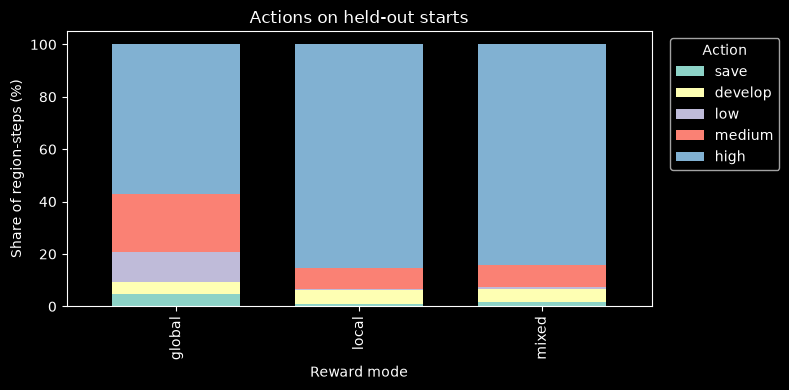

In [62]:
ax = (mean_fractions.rename(columns=ACTION_NAMES) * 100).plot.bar(
    stacked=True, figsize=(8, 4), width=0.7
)
ax.set(xlabel="Reward mode", ylabel="Share of region-steps (%)", title="Actions on held-out starts")
ax.legend(title="Action", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

- The graph makes the preference for high mitigation easier to see, especially under local and mixed rewards. The spending table below helps check whether those attempts became paid purchases.

## Do the four regions act differently?

In [63]:
region_counts = actions.groupby(
    ["reward_mode", "training_seed", "region", "action"]
).size().unstack(fill_value=0).reindex(columns=range(5), fill_value=0)
region_fractions = region_counts.div(region_counts.sum(axis=1), axis=0)
region_means = region_fractions.groupby(["reward_mode", "region"]).mean()

display((region_means.rename(columns=ACTION_NAMES) * 100).round(1))

action              save  develop   low  medium  high
reward_mode region                                   
global      0        1.4      3.0  39.9     7.8  48.0
            1       12.6      5.7   0.1    18.3  63.3
            2        0.3      4.8   1.8    40.6  52.4
            3        4.4      4.4   3.9    22.2  65.1
local       0        0.9      5.2   1.3     5.9  86.7
            1        0.5      5.2   0.2     4.1  90.0
            2        0.6      5.1   0.3    16.1  78.0
            3        1.4      6.6   0.1     4.5  87.4
mixed       0        4.1      4.6   2.7    16.8  71.8
            1        0.5      5.0   0.0     4.0  90.5
            2        0.3      5.0   0.8     5.3  88.6
            3        1.4      5.0   0.1     7.0  86.5

- Global region 0 stands out: it chooses low mitigation on 39.9% of steps, while the other global regions choose it on 0.1-3.9%.
- Local regions look more similar, though region 2 chooses high mitigation less often (78.0%) than the others (86.7-90.0%). Mixed region 0 also differs, choosing high mitigation on 71.8% versus 86.5-90.5% elsewhere.
- I would check these patterns for each training seed before calling them stable regional differences. Similar action frequencies also do not mean the four Q-tables make the same choice for every observation.

## How much do mitigation purchases cost?

- Low, medium, and high mitigation cost 10, 25, and 50 currency when a purchase is valid.
- Show the mean cost of a valid mitigation purchase and the total mitigation spending in an episode. Development spending is separate.

In [64]:
actions["mitigation_cost_paid"] = actions["cost_paid"].where(
    actions["action"].isin((2, 3, 4)), 0
)
episode_spending = actions.groupby(
    ["reward_mode", "training_seed", "environment_seed"]
)["mitigation_cost_paid"].sum()
spending_by_seed = episode_spending.groupby(["reward_mode", "training_seed"]).mean()

valid_mitigation = actions[actions["action"].isin((2, 3, 4)) & actions["valid"]]
purchase_cost_by_seed = valid_mitigation.groupby(
    ["reward_mode", "training_seed"]
)["cost_paid"].mean()

In [65]:
spending_table = pd.DataFrame({
    "cost_per_purchase": purchase_cost_by_seed.groupby("reward_mode").mean(),
    "spending_per_episode": spending_by_seed.groupby("reward_mode").mean(),
})
display(spending_table.round(1))

,cost_per_purchase,spending_per_episode
reward_mode,,
global,38.7,28233.9
local,47.8,35776.0
mixed,47.4,35460.4


- A valid high-mitigation purchase costs 50. The average paid purchase costs 47.8 under local reward and 47.4 under mixed reward, which supports the idea that they usually buy high mitigation. Global averages 38.7 and uses a broader mix.
- Local and mixed agents spend about 35,000 currency on mitigation per episode, compared with about 28,000 for global agents. This is the total across four regions and 200 steps.
- Could medium mitigation keep pollution low for less currency? The action counts and costs raise that question, but this table cannot answer it.

## Do regions reach EDI 100?

In [66]:
region_episodes = actions.groupby(
    ["reward_mode", "training_seed", "environment_seed", "region"]
).agg(final_edi=("edi_after", "last"))
region_episodes["reached_100"] = region_episodes["final_edi"].ge(100)

development_by_seed = region_episodes.groupby(
    ["reward_mode", "training_seed"]
).agg(mean_final_edi=("final_edi", "mean"),
      reached_100_percent=("reached_100", "mean"))
development_by_seed["reached_100_percent"] *= 100
development_table = development_by_seed.groupby("reward_mode").mean()

mitigation_attempts = actions[actions["action"].isin((2, 3, 4))]
before_100 = mitigation_attempts.groupby(
    ["reward_mode", "training_seed"]
)["edi_before"].apply(lambda edi: 100 * edi.lt(100).mean())
development_table["mitigation_before_100_percent"] = (
    before_100.groupby("reward_mode").mean()
)
display(development_table.round(1))

,mean_final_edi,reached_100_percent,mitigation_before_100_percent
reward_mode,,,
global,58.7,3.8,97.1
local,71.0,3.5,97.4
mixed,68.6,0.0,100.0


- Mean final EDI is 58.7 for global, 71.0 for local, and 68.6 for mixed. Only 3.8%, 3.5%, and 0.0% of region episodes reach EDI 100, respectively.

Note for self: The `reached_100_percent` column is about **development**, not pollution.


- About 97-100% of mitigation attempts happen while the acting region's EDI is below 100. The agents do not wait to finish development before mitigating.
- Development gains get smaller as EDI rises. I wonder if that makes further development less attractive, alongside the need to control pollution. These outcomes do not reveal an agent's intention.

## Actions at different global pollution levels

- Agents observe a shared pollution bin before choosing an action. Bin 0 is below 34, bin 1 is 34 to below 67, and bin 2 is 67 or higher.
- The table pools attempted actions from all held-out region-steps within each visited bin. `region_steps` shows how often that bin appeared.

In [51]:
global_counts = pd.crosstab(
    [actions["reward_mode"], actions["global_pollution_bin_before"]],
    actions["action"],
)
global_counts = global_counts.reindex(columns=range(5), fill_value=0)
visits = global_counts.sum(axis=1)
global_table = global_counts.div(visits, axis=0).rename(columns=ACTION_NAMES) * 100
global_table["region_steps"] = visits
display(global_table.round(1))

action                                   save  develop   low  medium  high  \
reward_mode global_pollution_bin_before                                      
global      0                             4.7      4.5  11.4    22.2  57.3   
            1                             3.6      7.1  20.1    43.3  25.9   
local       0                             0.8      5.5   0.4     7.5  85.8   
            1                             3.0     16.6   4.2    20.3  55.9   
mixed       0                             1.6      4.9   0.9     8.2  84.5   
            1                             2.0     14.5   4.4    28.8  50.2   

action                                   region_steps  
reward_mode global_pollution_bin_before                
global      0                                   79776  
            1                                     224  
local       0                                   79408  
            1                                     592  
mixed       0                                   79504  
            1                                     496

- Bin 0 means the Global Pollution Index is below 34; bin 1 means it is 34 to below 67. Bin 2 is never visited here.
- Bin 1 is rare: 224 global, 592 local, and 496 mixed region-steps, out of 80,000 in each mode. High mitigation appears less often in bin 1, but that small, unusual set of visits is not enough to say rising global pollution causes less mitigation.
- I would first ask when bin 1 occurs and what EDI and currency look like then. Those conditions may explain the action mix better than the global bin alone.

## How close did episodes get to failure?

- An episode fails if **any region's pollution load reaches 100**. The Global Pollution Index is the average of four loads; it does not need to reach 100 for failure.

In [67]:
episode_peaks = actions.groupby(
    ["reward_mode", "training_seed", "environment_seed"]
).agg(peak_global_index=("gpi_after", "max"),
      peak_regional_load=("pollution_after", "max"),
      failed=("failed", "max"))
episode_peaks["distance_below_100"] = 100 - episode_peaks["peak_regional_load"]

peaks_by_seed = episode_peaks.groupby(["reward_mode", "training_seed"]).mean()
peaks_by_seed["failure_percent"] = peaks_by_seed["failed"] * 100
peaks_by_seed = peaks_by_seed.drop(columns="failed")
display(peaks_by_seed.groupby("reward_mode").mean().round(1))

,peak_global_index,peak_regional_load,distance_below_100,failure_percent
reward_mode,,,,
global,31.0,41.0,59.0,0.0
local,36.0,41.5,58.5,0.0
mixed,35.3,41.1,58.9,0.0


- The average episode's highest regional load is about 41 in every mode, leaving roughly 59 pollution units below the failure threshold of 100. None of these held-out episodes fails.
- The peak Global Pollution Index is about 31-36. It is an average, while failure is triggered by a **regional** load of 100. These are pollution units, not percentages.
- The agents seem far from failure, which makes me wonder whether high mitigation is more than they need. The reward penalizes pollution even below the failure threshold, so a low failure rate alone does not show that high mitigation is wasted.